In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
archivo = next(iter(uploaded))

df = pd.read_excel(archivo,
    sheet_name="device_data",
    header=1)

df.columns = df.columns.astype(str).str.strip()
df["Local Date Time"] = pd.to_datetime(
    df["Local Date Time"], errors="coerce")

inicio = pd.Timestamp("2026-10-26 10:30:00")
fin = pd.Timestamp("2026-10-26 14:30:00")

df = df[df["Local Date Time"].between(inicio, fin)].copy()

def extraer_numero(columna):
    return pd.to_numeric(
        df[columna].astype(str)
        .str.extract(r"(-?\d+(?:\.\d+)?)")[0],
        errors="coerce")

resultado = pd.DataFrame({"Fecha y hora": df["Local Date Time"],
    "Temperatura (°C)": extraer_numero("Temperature Outdoor"),
    "Presión atmosférica (hPa)": (
        extraer_numero("Pressure Absolute") * 33.8639),
    "Humedad relativa exterior (%)": (
        extraer_numero("Humidity Outdoor")),
    "Velocidad del viento (km/h)": (
        extraer_numero("Wind Average"))})

resultado = resultado.sort_values("Fecha y hora")
nombre_salida = "registro 2610.xlsx"
resultado.to_excel(nombre_salida, index=False)
print("Total de registros encontrados:", len(resultado))
display(resultado)

files.download(nombre_salida)


Saving registro 2610.xlsx to registro 2610.xlsx
Total de registros encontrados: 49


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Fecha y hora,Temperatura (°C),Presión atmosférica (hPa),Humedad relativa exterior (%),Velocidad del viento (km/h)
125,2026-10-26 10:30:00,18.7,702.675925,59,12.92
126,2026-10-26 10:35:00,19.0,702.675925,58,15.16
127,2026-10-26 10:40:00,19.1,702.675925,55,15.88
128,2026-10-26 10:45:00,19.3,702.675925,54,14.58
129,2026-10-26 10:50:00,19.3,702.675925,52,15.80
130,2026-10-26 10:55:00,19.1,702.675925,54,12.13
131,2026-10-26 11:00:00,19.0,702.337286,53,15.05
132,2026-10-26 11:05:00,19.0,702.337286,56,12.35
133,2026-10-26 11:10:00,19.0,702.337286,57,9.50
134,2026-10-26 11:15:00,19.9,702.337286,56,8.46


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install openpyxl scikit-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from google.colab import files

In [ ]:
print("Sube los dos archivos Excel:")
uploaded = files.upload()

print("\nArchivos cargados:")
for nombre in uploaded.keys():
    print(nombre)

Sube los dos archivos Excel:


Saving registro_26_oct_2026.xlsx to registro_26_oct_2026 (1).xlsx
Saving registro  4 variables_predichas 2610 (1).xlsx to registro  4 variables_predichas 2610 (1) (1).xlsx

Archivos cargados:
registro_26_oct_2026 (1).xlsx
registro  4 variables_predichas 2610 (1) (1).xlsx


In [ ]:
import pandas as pd
import numpy as np

# Identificar archivos cargados en Colab
archivo_registro = next(
    (f for f in uploaded if "registro" in f.lower()), None)

archivo_predicciones = next(
    (f for f in uploaded if "predichas" in f.lower()), None)

if archivo_registro is None or archivo_predicciones is None:
    raise ValueError("No se encontraron ambos archivos. "
        "Verifica que hayas subido el registro y las predicciones.")

registro = pd.read_excel(archivo_registro, header=1)
registro.columns = registro.columns.astype(str).str.strip()

pred = pd.read_excel(archivo_predicciones, header=0)
pred.columns = pred.columns.astype(str).str.strip()

print("Columnas del registro:")
print(registro.columns.tolist())

print("\nColumnas de predicciones:")
print(pred.columns.tolist())

registro["FechaHora"] = pd.to_datetime(
    registro["fecha"].astype(str).str.strip() + " " +
    registro["hora"].astype(str).str.strip(),
    errors="coerce")

col_fecha_pred = "Fecha y hora"
pred["FechaHora"] = pd.to_datetime(
    pred[col_fecha_pred], errors="coerce")

columnas_registro = ["temperatura  (°C)",
    "presion atmosferica hPa",
    "humedad relativa %",
    "velocidad del viento km/h"]

for col in columnas_registro:
    registro[col] = pd.to_numeric(
        registro[col], errors="coerce")


columnas_pred = ["Temperatura (°C)",
    "Presión atmosférica (hPa)",
    "Humedad relativa exterior (%)",
    "Velocidad del viento (km/h)"]

for col in columnas_pred:
    pred[col] = pd.to_numeric(
        pred[col], errors="coerce")

pred = pred.rename(columns={
    "Temperatura (°C)": "Temperatura_pred",
    "Presión atmosférica (hPa)": "Presion_pred",
    "Humedad relativa exterior (%)": "Humedad_pred",
    "Velocidad del viento (km/h)": "Viento_pred"})

registro_limpio = registro[["FechaHora",
    "temperatura  (°C)",
    "presion atmosferica hPa",
    "humedad relativa %",
    "velocidad del viento km/h"
]].dropna(subset=["FechaHora"])

pred_limpio = pred[["FechaHora",
    "Temperatura_pred",
    "Presion_pred",
    "Humedad_pred",
    "Viento_pred"]].dropna(subset=["FechaHora"])

datos = pd.merge(registro_limpio,
    pred_limpio,
    on="FechaHora",
    how="inner")

datos = datos.sort_values("FechaHora").reset_index(drop=True)

print("\nDatos comparables encontrados:", len(datos))
display(datos.head(10))

if datos.empty:
    raise ValueError(
        "No se encontraron fechas y horas coincidentes. "
        "Revisa los formatos de fecha y hora de ambos archivos.")


Columnas del registro:
['fecha', 'hora', 'temperatura  (°C)', 'presion atmosferica hPa', 'humedad relativa %', 'velocidad del viento km/h']

Columnas de predicciones:
['Fecha y hora', 'Temperatura (°C)', 'Presión atmosférica (hPa)', 'Humedad relativa exterior (%)', 'Velocidad del viento (km/h)']

Datos comparables encontrados: 49


,FechaHora,temperatura (°C),presion atmosferica hPa,humedad relativa %,velocidad del viento km/h,Temperatura_pred,Presion_pred,Humedad_pred,Viento_pred
0,2026-10-26 10:30:00,18.5,701,39.1,10.5,18.7,702.675925,41,12.92
1,2026-10-26 10:35:00,20.1,701,40.0,12.5,19.0,702.675925,40,15.16
2,2026-10-26 10:40:00,21.8,701,40.0,13.8,19.1,702.675925,40,15.88
3,2026-10-26 10:45:00,22.2,701,39.0,15.3,19.3,702.675925,42,14.58
4,2026-10-26 10:50:00,21.6,701,40.8,12.3,19.3,702.675925,41,15.80
5,2026-10-26 10:55:00,21.7,701,41.4,13.2,19.1,702.675925,41,12.13
6,2026-10-26 11:00:00,21.6,701,41.9,14.5,19.0,702.337286,41,15.05
7,2026-10-26 11:05:00,21.5,702,42.4,15.3,19.0,702.337286,40,12.35
8,2026-10-26 11:10:00,21.4,702,42.9,10.4,19.0,702.337286,42,9.50
9,2026-10-26 11:15:00,21.3,702,43.5,9.8,19.9,702.337286,42,8.46


In [ ]:
variables = {
    "Temperatura (°C)": (
        "temperatura  (°C)", "Temperatura_pred"),
    "Presión atmosférica (hPa)": (
        "presion atmosferica hPa", "Presion_pred"),
    "Humedad relativa (%)": (
        "humedad relativa %", "Humedad_pred"),
    "Velocidad del viento (km/h)": (
        "velocidad del viento km/h", "Viento_pred")}

resultados = []
datos_metricas = {}
for nombre, (col_real, col_pred) in variables.items():

    temp = datos[[col_real, col_pred]].dropna()
    y_real = temp[col_real]
    y_pred = temp[col_pred]

    if len(temp) < 2:
        print(f"No hay suficientes datos para {nombre}")
        continue

    r2 = r2_score(y_real, y_pred)
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)

    resultados.append({
        "Variable": nombre,
        "N": len(temp),
        "R²": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse})

    datos_metricas[nombre] = (y_real, y_pred)
tabla_metricas = pd.DataFrame(resultados)

print("RESULTADOS DE EVALUACIÓN")
display(tabla_metricas.style.format({
        "R²": "{:.4f}",
        "MAE": "{:.4f}",
        "MSE": "{:.4f}",
        "RMSE": "{:.4f}"}))

RESULTADOS DE EVALUACIÓN


,Variable,N,R²,MAE,MSE,RMSE
0,Temperatura (°C),49,-0.6916,1.1367,1.9782,1.4065
1,Presión atmosférica (hPa),49,-0.6485,1.2449,2.1037,1.4504
2,Humedad relativa (%),49,0.9223,1.9429,5.8420,2.4170
3,Velocidad del viento (km/h),49,0.5592,1.7220,4.6849,2.1645


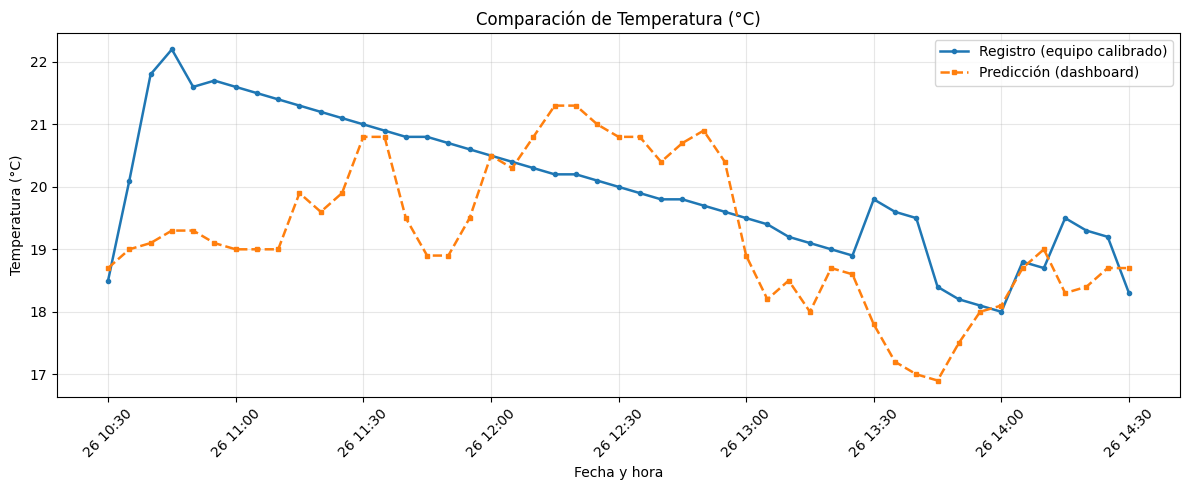

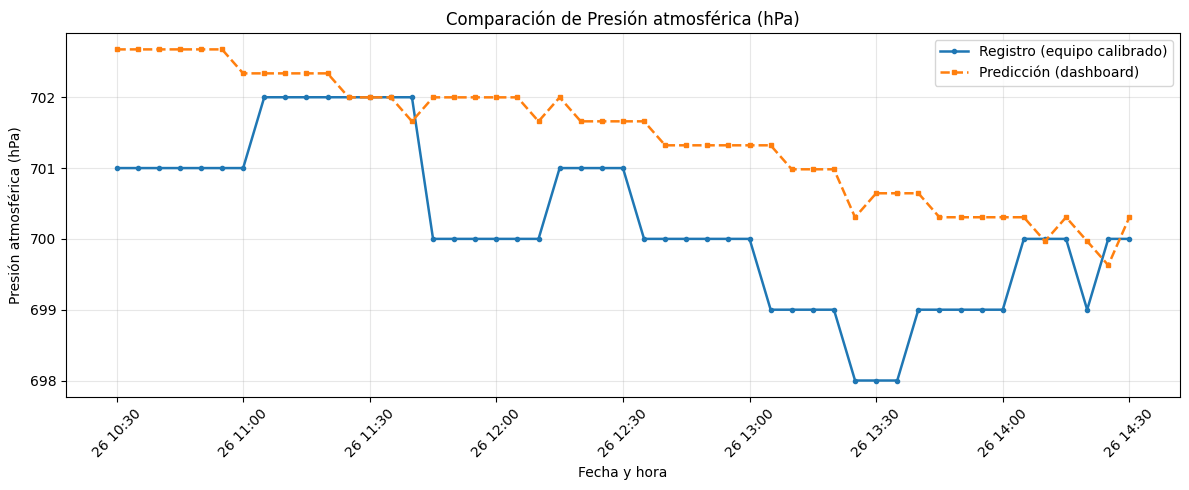

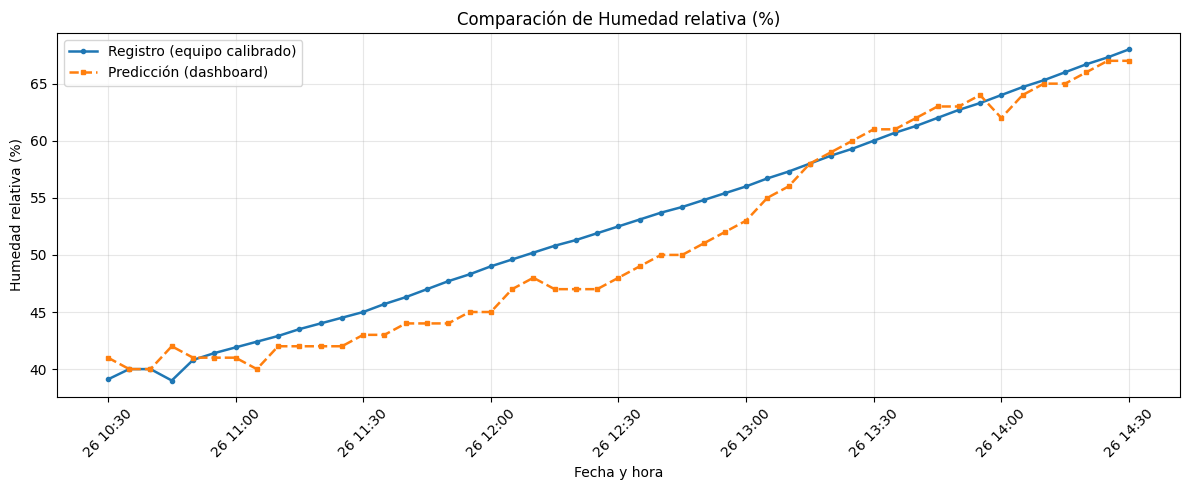

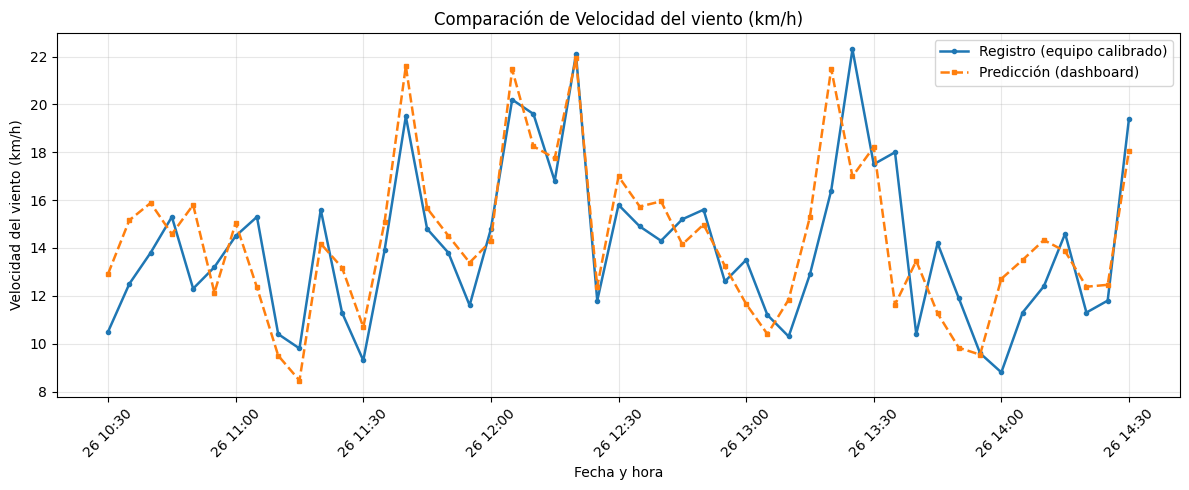

In [ ]:
for nombre, (col_real, col_pred) in variables.items():

    plt.figure(figsize=(12, 5))

    plt.plot(
        datos["FechaHora"],
        datos[col_real],
        marker="o",
        markersize=3,
        linewidth=1.8,
        label="Registro (equipo calibrado)"
    )

    plt.plot(
        datos["FechaHora"],
        datos[col_pred],
        marker="s",
        markersize=3,
        linewidth=1.8,
        linestyle="--",
        label="Predicción (dashboard)"
    )

    plt.title(f"Comparación de {nombre}")
    plt.xlabel("Fecha y hora")
    plt.ylabel(nombre)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()